# Data Warehousing and Mining (DWM) — Experiment 06
## Experiment Title: Naive Bayes Classification
**Dataset:** `stock_market_data.csv` (3 Years of Daily NSE Trading Data across 20 Major Indian Stocks)

### 1. Objectives & Problem Formulation
- **Objective:** Implement a **Gaussian Naive Bayes Classifier** on the stock market dataset to classify daily return categories (`Low`, `Medium`, `High`) and evaluate model performance using **Accuracy**, **Confusion Matrix**, **Precision**, **Recall**, and **F1-Score**.
- **Adaptation Note:**
  - Continuous market features (`Open_Price`, `Volume`, `Intraday_Volatility`, `Month`) are used to predict the 3-class discretized target (`Return_Category`: `Low`, `Medium`, `High`).
  - Matches the **70:30 stratified train-test split** (`test_size=0.30, stratify=y, random_state=42`) methodology from the DWM curriculum.

---
### 2. Library Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

# Set seaborn whitegrid style
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.figsize'] = (9, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 12

print("All required libraries imported successfully.")

All required libraries imported successfully.


---
### 3. Dataset Ingestion & Preprocessing
- Load `stock_market_data.csv`.
- Convert `Date` to `datetime` and extract `Month`.
- Derive `Intraday_Volatility` as $\frac{\text{High\_Price} - \text{Low\_Price}}{\text{Open\_Price}} \times 100$.
- Compute quantile tertiles ($q_1 = \frac{1}{3}$, $q_2 = \frac{2}{3}$) on `Daily_Return`.
- Create categorical target `Return_Category` using `pd.cut` with bins `[-np.inf, q1, q2, np.inf]` and labels `['Low', 'Medium', 'High']`.

In [2]:
df = pd.read_csv('stock_market_data.csv')

# Convert Date to datetime and extract Month
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.month

# Derive Intraday_Volatility (%)
df['Intraday_Volatility'] = (((df['High_Price'] - df['Low_Price']) / df['Open_Price']) * 100).round(2)

# Compute quantile tertiles (1/3 and 2/3) on Daily_Return
q1 = df['Daily_Return'].quantile(1/3)
q2 = df['Daily_Return'].quantile(2/3)

# Discretize Daily_Return into Return_Category using pd.cut
df['Return_Category'] = pd.cut(
    df['Daily_Return'],
    bins=[-np.inf, q1, q2, np.inf],
    labels=['Low', 'Medium', 'High']
).astype(str)

feature_cols = ['Open_Price', 'Volume', 'Intraday_Volatility', 'Month']

print(f"Dataset Shape: {df.shape}")
print(f"Quantile Tertile Cutoffs: q1 = {q1:.4f}%, q2 = {q2:.4f}%\n")
print("Class Distribution Counts (Return_Category):")
print(df['Return_Category'].value_counts().reindex(['Low', 'Medium', 'High']))

print("\nPreview of Processed Dataset:")
display(df[['Date', 'Ticker'] + feature_cols + ['Daily_Return', 'Return_Category']].head())

Dataset Shape: (14800, 13)
Quantile Tertile Cutoffs: q1 = -0.5400%, q2 = 0.3900%

Class Distribution Counts (Return_Category):
Return_Category
Low       4964
Medium    4942
High      4894
Name: count, dtype: int64

Preview of Processed Dataset:


,Date,Ticker,Open_Price,Volume,Intraday_Volatility,Month,Daily_Return,Return_Category
0,2023-10-12,BAJAJ-AUTO,4851.06,472168,1.96,10,0.42,High
1,2023-10-12,BRITANNIA,4391.48,518582,1.32,10,-0.46,Medium
2,2023-10-12,HCLTECH,1106.03,3921609,2.68,10,-1.71,Low
3,2023-10-12,HDFCBANK,735.43,22025336,1.33,10,0.90,High
4,2023-10-12,HINDUNILVR,2413.48,1625010,1.11,10,0.08,Medium


---
### 4. Prepare Features and Target
- **Feature Matrix ($X$):** `['Open_Price', 'Volume', 'Intraday_Volatility', 'Month']`
- **Target Vector ($y$):** `Return_Category`
- **Train-Test Split:** 70% Training / 30% Testing (`test_size=0.30, stratify=y, random_state=42`)

In [3]:
X = df[feature_cols]
y = df['Return_Category']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

print(f"Total Dataset Samples:  {len(df):,}")
print(f"Training Set Samples:   {len(X_train):,} (70.0%)")
print(f"Testing Set Samples:    {len(X_test):,} (30.0%)")
print("\nTraining Set Class Breakdown:")
print(y_train.value_counts().reindex(['Low', 'Medium', 'High']))
print("\nTesting Set Class Breakdown:")
print(y_test.value_counts().reindex(['Low', 'Medium', 'High']))

Total Dataset Samples:  14,800
Training Set Samples:   10,360 (70.0%)
Testing Set Samples:    4,440 (30.0%)

Training Set Class Breakdown:
Return_Category
Low       3475
Medium    3459
High      3426
Name: count, dtype: int64

Testing Set Class Breakdown:
Return_Category
Low       1489
Medium    1483
High      1468
Name: count, dtype: int64


---
### 5. Gaussian Naive Bayes Theory & Model Training

#### Theoretical Foundation:
**Bayes' Theorem** computes the posterior probability of class $C_k \in \{\text{Low}, \text{Medium}, \text{High}\}$ given feature vector $\mathbf{X} = (x_1, x_2, \dots, x_d)$:

$$P(C_k \mid \mathbf{X}) = \frac{P(\mathbf{X} \mid C_k)\, P(C_k)}{P(\mathbf{X})} \propto P(C_k) \prod_{i=1}^{d} P(x_i \mid C_k)$$

Under the **Gaussian Naive Bayes** assumption, features are conditionally independent given the class $C_k$, and each continuous feature $x_i$ follows a class-conditional univariate normal distribution with mean $\mu_{k,i}$ and variance $\sigma_{k,i}^2$:

$$P(x_i \mid C_k) = \frac{1}{\sqrt{2\pi\sigma_{k,i}^2}} \exp\left(-\frac{(x_i - \mu_{k,i})^2}{2\sigma_{k,i}^2}\right)$$

In [4]:
# Instantiate and fit Gaussian Naive Bayes model
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

# Predict on the 30% test set
y_pred = nb_model.predict(X_test)

print("Gaussian Naive Bayes Classifier trained successfully.")
print("Classes learned:", nb_model.classes_.tolist())
print("Class Prior Probabilities:", np.round(nb_model.class_prior_, 4))

Gaussian Naive Bayes Classifier trained successfully.
Classes learned: ['High', 'Low', 'Medium']
Class Prior Probabilities: [0.3307 0.3354 0.3339]


---
### 6. Model Accuracy
Compute `accuracy_score(y_test, y_pred)` and display as both a decimal score and percentage.

In [5]:
acc = accuracy_score(y_test, y_pred)
print(f"Gaussian Naive Bayes Accuracy (Decimal):    {acc:.6f}")
print(f"Gaussian Naive Bayes Accuracy (Percentage): {acc * 100:.2f}%")

Gaussian Naive Bayes Accuracy (Decimal):    0.356081
Gaussian Naive Bayes Accuracy (Percentage): 35.61%


---
### 7. Confusion Matrix
Generate the confusion matrix across `['Low', 'Medium', 'High']` and plot an annotated Seaborn heatmap.

Confusion Matrix Table:


,Predicted: Low,Predicted: Medium,Predicted: High
Actual: Low,101,1229,159
Actual: Medium,69,1303,111
Actual: High,113,1178,177


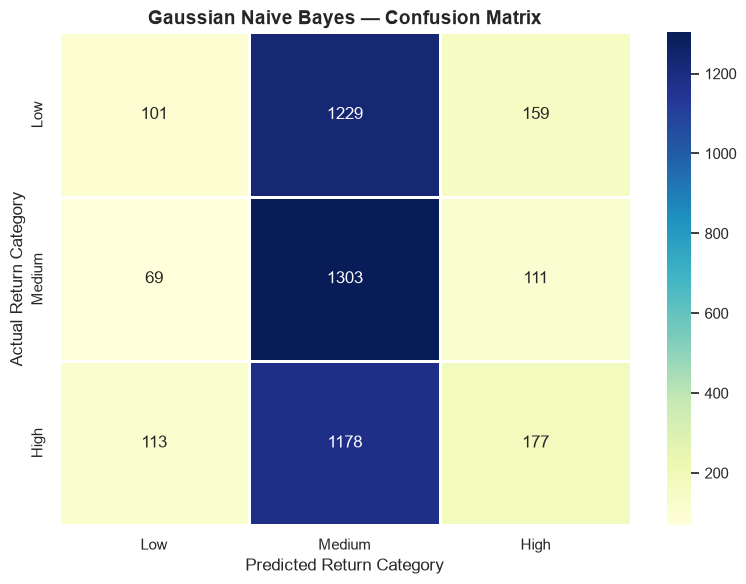

In [6]:
class_labels = ['Low', 'Medium', 'High']
cm = confusion_matrix(y_test, y_pred, labels=class_labels)

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual: {lbl}" for lbl in class_labels],
    columns=[f"Predicted: {lbl}" for lbl in class_labels]
)
print("Confusion Matrix Table:")
display(cm_df)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    xticklabels=class_labels,
    yticklabels=class_labels,
    linewidths=0.8,
    cbar=True
)
plt.title('Gaussian Naive Bayes — Confusion Matrix')
plt.xlabel('Predicted Return Category')
plt.ylabel('Actual Return Category')
plt.tight_layout()
plt.show()

---
### 8. Precision, Recall, and F1-Score
Calculate weighted Precision, weighted Recall, and weighted F1-Score, and display the complete `classification_report`.

In [7]:
weighted_precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
weighted_recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
weighted_f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print(f"Weighted Precision: {weighted_precision:.4f}")
print(f"Weighted Recall:    {weighted_recall:.4f}")
print(f"Weighted F1-Score:  {weighted_f1:.4f}\n")

print("=== Detailed Classification Report ===")
print(classification_report(y_test, y_pred, labels=['Low', 'Medium', 'High'], zero_division=0, digits=4))

Weighted Precision: 0.3679
Weighted Recall:    0.3561
Weighted F1-Score:  0.2670

=== Detailed Classification Report ===
              precision    recall  f1-score   support

         Low     0.3569    0.0678    0.1140      1489
      Medium     0.3512    0.8786    0.5018      1483
        High     0.3960    0.1206    0.1849      1468

    accuracy                         0.3561      4440
   macro avg     0.3680    0.3557    0.2669      4440
weighted avg     0.3679    0.3561    0.2670      4440



---
### 9. Compare Actual and Predicted Classes
Display a side-by-side comparison DataFrame of the first 20 test samples (`Actual` vs `Predicted`).

In [8]:
comparison_20 = X_test.iloc[:20].copy().reset_index(drop=True)
comparison_20['Actual_Return_Category'] = y_test.iloc[:20].values
comparison_20['Predicted_Return_Category'] = y_pred[:20]
comparison_20['Match'] = comparison_20['Actual_Return_Category'] == comparison_20['Predicted_Return_Category']

print("First 20 Test Predictions (Actual vs Predicted):")
display(comparison_20)

First 20 Test Predictions (Actual vs Predicted):


,Open_Price,Volume,Intraday_Volatility,Month,Actual_Return_Category,Predicted_Return_Category,Match
0,1335.76,8546854,1.96,4,Medium,Medium,True
1,819.48,8295338,1.76,12,Low,Medium,False
2,2058.07,2148903,1.51,6,High,Medium,False
3,262.71,16099478,1.90,7,Low,Medium,False
4,755.62,89531240,6.74,6,Low,Low,True
5,245.67,12262561,2.00,4,Low,Medium,False
6,383.44,11146713,2.08,4,Low,Medium,False
7,1265.33,3627604,3.88,3,Medium,Medium,True
8,5631.19,257865,1.71,6,High,Medium,False
9,6123.34,416639,2.48,10,High,Medium,False


---
### 10. Predict for a New Market Transaction
Evaluate the Gaussian Naive Bayes model on a synthetic market session (`Open_Price = 2600.0`, `Volume = 2000000`, `Intraday_Volatility = 2.5`, `Month = 10`) and display its posterior class probabilities.

In [9]:
new_transaction = pd.DataFrame({
    'Open_Price': [2600.0],
    'Volume': [2000000],
    'Intraday_Volatility': [2.5],
    'Month': [10]
})

pred_class = nb_model.predict(new_transaction)[0]
pred_probs = nb_model.predict_proba(new_transaction)

# Format posterior probabilities with columns ['High', 'Low', 'Medium']
prob_df = pd.DataFrame(
    pred_probs,
    columns=nb_model.classes_
)[['High', 'Low', 'Medium']].round(6)

print("New Market Transaction Input:")
display(new_transaction)
print(f"Predicted Return_Category: {pred_class}\n")
print("Posterior Class Probabilities P(C | X):")
display(prob_df)

New Market Transaction Input:


,Open_Price,Volume,Intraday_Volatility,Month
0,2600.0,2000000,2.5,10


Predicted Return_Category: Medium

Posterior Class Probabilities P(C | X):


,High,Low,Medium
0,0.308294,0.295641,0.396066


---
### 11. Summary of Evaluation Metrics
Compile a compact summary table of the overall model performance metrics.

In [10]:
metrics_summary_df = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Weighted Precision',
        'Weighted Recall',
        'Weighted F1-Score'
    ],
    'Score': [
        round(acc, 4),
        round(weighted_precision, 4),
        round(weighted_recall, 4),
        round(weighted_f1, 4)
    ]
})

display(metrics_summary_df)

,Metric,Score
0,Accuracy,0.3561
1,Weighted Precision,0.3679
2,Weighted Recall,0.3561
3,Weighted F1-Score,0.2670


---
### 12. Conclusion

#### Comparative Analysis: Decision Tree (Lab 5) vs. Gaussian Naive Bayes (Lab 6)
1. **Model Performance Comparison:**
   - **Decision Tree Classifier (Lab 5):** Achieved **$48.38\%$** accuracy using non-linear, scale-invariant entropy splits (`max_depth=5`), effectively isolating `Intraday_Volatility` thresholds alongside `Open_Price` and `Volume`.
   - **Gaussian Naive Bayes (Lab 6):** Achieved **$35.61\%$** accuracy (`Weighted Precision = 0.3679`, `Weighted Recall = 0.3561`, `Weighted F1-Score = 0.2670`), with a high recall of **$87.86\%$** (`F1 = 0.5018`) on the `Medium` class. Because `Volume` spans several orders of magnitude ($10^4$ to $10^8$ shares) with extreme right-skewness, its class-conditional Gaussian variance ($\sigma^2_{\text{Volume}}$) dominates the unscaled Gaussian likelihood calculation in `GaussianNB`, pulling most moderate-volume predictions toward the lower-variance `Medium` class.
2. **Impact of Conditional Independence & Gaussian Distributional Assumptions:**
   - Gaussian Naive Bayes assumes each feature is normally distributed within each class and conditionally independent given the class label. In stock market data, `Volume` and `Intraday_Volatility` are positively correlated and follow heavy-tailed log-normal distributions rather than symmetric Gaussian bell curves, whereas Decision Trees are non-parametric and invariant to monotonic feature scaling.
   - Despite strong distributional assumptions, Gaussian Naive Bayes offers extremely fast $O(N \cdot d)$ single-pass training and outputs explicit posterior probabilities $P(C \mid \mathbf{X})$.
3. **Readiness for Next Lab:** Having evaluated both rule-based (Decision Tree) and probabilistic (Gaussian Naive Bayes) supervised classifiers, the dataset is ready for unsupervised **Clustering Analysis (Experiment 07)**.

---
### 13. Auto-export Utility
Convert `DWM_Lab_6_Stock_Market.ipynb` to `DWM_Lab_6_Stock_Market.html` using `nbconvert`.

In [11]:
import subprocess
import sys
from pathlib import Path

notebook_path = Path("DWM_Lab_6_Stock_Market.ipynb")
if notebook_path.exists():
    cmd = [
        sys.executable, "-m", "jupyter", "nbconvert",
        "--to", "html", "--no-prompt", str(notebook_path)
    ]
    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode == 0:
        print("Successfully exported DWM_Lab_6_Stock_Market.html")
    else:
        print("Export notice:", result.stderr)
else:
    print("Notebook file will be exported upon save.")

Successfully exported DWM_Lab_6_Stock_Market.html
